### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# SLC38A4-KO: clone-level robustness check for GSEA claims

**Purpose (internal — not a manuscript figure).** Every pre-ranked GSEA result reported in the paper —
Fig. 4E (SLC38A4-KO vs SAH liver signature), Fig. S8B (SLC38A4-KO vs hepatocyte developmental
signatures), and Fig. 3D/Table S6 (SLC38A4-KO vs KEGG/Hallmark/Reactome/curated pathway gene sets) — is
run on the **pooled** KO-vs-WT contrast (`Fig3C_limma_KO_vs_WT_combined_mincount10.csv`), i.e. KO1 (clone C12) and
KO2 (clone P1.7) combined into one differential-expression model. This notebook re-runs the *same* GSEA,
on the *same* gene sets, separately for **KO1 vs WT** and **KO2 vs WT** (`FigS7_limma_KO1_vs_WT_mincount10.csv`,
`FigS7_limma_KO2_vs_WT_mincount10.csv`) and compares all three (pooled / KO1 / KO2) side by side, panel by panel.
The question for each panel is simple: is the pooled result something both clones actually show, or is
it driven by one clone and diluted/contradicted by the other?

This matters because an internal per-sample module-score check (not itself a manuscript figure --
see `DevSig_module_scores.csv`, from `SLC38A4_KO_developmental_signature_analysis.ipynb`) already
found one clear case of this:
the Hepatoblast and Adult-hepatocyte developmental signatures move in **opposite directions** between
KO1 and KO2 at the per-sample level, even though the pooled GSEA reports a significant FDR for both.
Only the Fetal-hepatocyte signature (and, separately, AFP/HNF4A-P2) held up as clone-concordant. Panels
1–2 below check whether that same discordance shows up at the pathway (GSEA) level for SAH-concordance
and developmental signatures. Panel 3 does the same for the 9 hand-curated gene modules behind Fig.
3D/3E/4 (amino-acid transport, urea cycle, proliferation, epithelial/mesenchymal identity, etc.) — and,
reassuringly, finds these are largely clone-concordant, unlike the developmental panels. Panel 4 covers
the KEGG/Hallmark/Reactome GSEA behind the rest of Fig. 3D/Table S6, but needs to be run in an
environment with internet access to Enrichr (see that section for why).

**Scope note.** `Fig3_KO_RNAseq_metabolism.ipynb` actually runs *nine* pathway-enrichment analyses
for Fig. 3D/Table S6: four Enrichr over-representation tests (ORA, on significant up/down gene lists —
a different statistical question, not covered here) and five pre-ranked GSEAs (all covered: the 9
curated modules in Panel 3; KEGG_2021_Human/Hallmark/Reactome in Panel 4).

**Inputs** (same folder as the other `06_Notebooks_for_GitHub` notebooks):
- `Fig3C_limma_KO_vs_WT_combined_mincount10.csv`, `FigS7_limma_KO1_vs_WT_mincount10.csv`, `FigS7_limma_KO2_vs_WT_mincount10.csv` — limma-voom
  results, one row per gene, `t` = moderated t-statistic used for ranking. Global concordance check:
  KO1 vs KO2 t-statistics correlate at r=0.71 across all 14,108 genes; each clone correlates ~0.92 with
  the pooled contrast (expected, since pooling averages the two).
- `Fig4E_SAH_signature_genes.csv` — the SAH-up/SAH-down 200-gene signature used for Fig. 4E (wide
  format: one `SAH_UP`/`SAH_DOWN` column per gene set).
- `reference/liver_developmental_signatures.gmt` — the Hepatoblast_HB / Fetal_hepatocyte_FH /
  Adult_hepatocyte_AH gene sets used for Fig. S8B (already committed to this repo's own `reference/`
  subfolder alongside `SLC38A4_KO_developmental_signature_analysis.ipynb`, 2026-08-14).
- `DevSig_module_scores.csv` — per-sample module z-scores (reused here for the per-sample cross-check).

Where a required file isn't found, the loader raises a clear error naming the exact file rather than
silently skipping or fabricating a result — so this notebook is safe to re-run later if any input moves.

In [2]:
import os
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import gseapy as gp

AXTITLE = 10
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':10,'axes.linewidth':1.0,'axes.spines.top':False,'axes.spines.right':False,
    'xtick.major.width':1.0,'ytick.major.width':1.0,'pdf.fonttype':42,'ps.fonttype':42,
    'axes.unicode_minus':False})
COLORS = {'Pooled':'#4d4d4d','KO 1':'#D73027','KO 2':'#FC8D59'}
CONTRASTS = ['Pooled','KO 1','KO 2']

DATA_DIR = '.'   # adjust if running from elsewhere; all three limma CSVs live alongside this notebook

def load_de(path):
    return (pd.read_csv(path, index_col=0)
              .dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol'))

DE = {
    'Pooled': load_de(os.path.join(DATA_DIR, 'Fig3C_limma_KO_vs_WT_combined_mincount10.csv')),
    'KO 1':   load_de(os.path.join(DATA_DIR, 'FigS7_limma_KO1_vs_WT_mincount10.csv')),
    'KO 2':   load_de(os.path.join(DATA_DIR, 'FigS7_limma_KO2_vs_WT_mincount10.csv')),
}
for k, v in DE.items():
    print(f'{k}: {len(v)} genes, t-stat range [{v["t"].min():.1f}, {v["t"].max():.1f}]')

def ranked_metric(contrast, seed=0):
    """Pre-ranked list for gseapy: t-statistic, tie-broken with a tiny seeded jitter"""
    rng = np.random.default_rng(seed)
    t = DE[contrast]['t'].astype(float)
    rnk = (t + rng.normal(0, 1e-9, len(t))).sort_values(ascending=False)
    return rnk.reset_index().rename(columns={rnk.index.name or 'index': 'gene', 0: 'score'}).set_axis(['gene','score'], axis=1)

def run_prerank(contrast, gene_sets, label, seed=0, permutation_num=2000):
    rnk = ranked_metric(contrast, seed=seed)
    res = gp.prerank(rnk=rnk, gene_sets=gene_sets, min_size=5, max_size=2000,
                      permutation_num=permutation_num, seed=seed, outdir=None, verbose=False)
    df = res.res2d.copy()
    df['contrast'] = label
    return df

Pooled: 14108 genes, t-stat range [-60.5, 49.2]
KO 1: 14108 genes, t-stat range [-48.1, 48.3]
KO 2: 14108 genes, t-stat range [-54.9, 62.6]


## Panel 1 — SAH liver-signature concordance (cf. Fig. 4E)

Same ranking metric and gene sets as the manuscript panel: SAH-up / SAH-down (top/bottom 200
protein-coding genes of the InTEAM SAH-vs-normal contrast, padj<0.05), tested by pre-ranked GSEA
against Pooled, KO1, and KO2 rankings in turn.

In [3]:
SAH_GMT_CANDIDATES = [
    'Fig4E_SAH_signature_genes.csv',        # wide {SAH_UP, SAH_DOWN} export, one gene per row, as
                                             # actually distributed alongside Fig4_KO_RNAseq_dedifferentiation.ipynb
    '_gsea_tmp/SAH_signature.gmt',          # .gmt written by the original Fig4 notebook's RECOMPUTE=True path
]

def load_sah_gene_sets():
    for path in SAH_GMT_CANDIDATES:
        if not os.path.exists(path):
            continue
        if path.endswith('.gmt'):
            gs = {}
            with open(path) as fh:
                for line in fh:
                    parts = line.rstrip('\n').split('\t')
                    gs[parts[0]] = [g for g in parts[2:] if g]
            return gs
        else:
            # wide format: one column per gene set (SAH_UP, SAH_DOWN), genes down the rows,
            # ragged columns padded with NaN if set sizes differ
            df = pd.read_csv(path)
            return {col: sorted(df[col].dropna().astype(str).tolist()) for col in df.columns}
    raise FileNotFoundError(
        "Couldn't find the SAH-up/SAH-down gene lists. Expected 'Fig4E_SAH_signature_genes.csv' "
        "(wide SAH_UP/SAH_DOWN columns) or '_gsea_tmp/SAH_signature.gmt' (as written by "
        "Fig4_KO_RNAseq_dedifferentiation.ipynb's RECOMPUTE=True block) next to this notebook. "
        "Either copy one of those files here, or re-run that notebook's RECOMPUTE=True cell "
        "(needs '../05_Data/RNAseq/SLC38A4_KO_RNA-seq/limma_KO_vs_WT_combined_mincount10.csv' and "
        "'../05_Data/RNAseq/inteam_res_complete_20251023.xlsx') to regenerate it."
    )

sah_gene_sets = load_sah_gene_sets()
print({k: len(v) for k, v in sah_gene_sets.items()})

{'SAH_UP': 200, 'SAH_DOWN': 200}


In [4]:
sah_rows = []
for contrast in CONTRASTS:
    df = run_prerank(contrast, sah_gene_sets, contrast)
    sah_rows.append(df)
sah_all = pd.concat(sah_rows, ignore_index=True)[['contrast','Term','ES','NES','NOM p-val','FDR q-val']]
sah_all.to_csv('GSEA_clonecheck_SAH_signature.csv', index=False)
sah_all

,contrast,Term,ES,NES,NOM p-val,FDR q-val
0,Pooled,SAH_UP,0.402897,1.770313,0.000000,0.000000
1,Pooled,SAH_DOWN,-0.341711,-1.438106,0.004902,0.004510
2,KO 1,SAH_UP,0.383381,1.663278,0.000000,0.000000
3,KO 1,SAH_DOWN,-0.311208,-1.377475,0.011136,0.012015
4,KO 2,SAH_UP,0.431761,1.845407,0.000000,0.000000
5,KO 2,SAH_DOWN,-0.274493,-1.199764,0.081986,0.082386


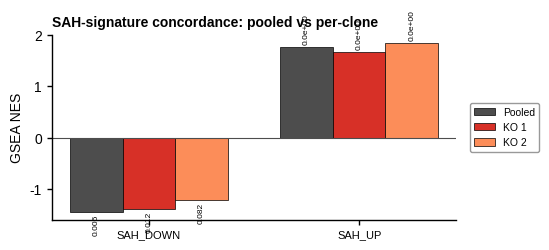

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 2.6))
terms = sorted(sah_all['Term'].unique())
w = 0.25
for i, contrast in enumerate(CONTRASTS):
    sub = sah_all[sah_all.contrast == contrast].set_index('Term').reindex(terms)
    x = np.arange(len(terms)) + (i - 1) * w
    ax.bar(x, sub['NES'], width=w, color=COLORS[contrast], edgecolor='black', linewidth=0.5, label=contrast)
    for xi, (nes, fdr) in zip(x, zip(sub['NES'], sub['FDR q-val'])):
        ax.text(xi, nes + (0.05 if nes >= 0 else -0.05), f'{fdr:.1e}' if fdr < 1e-3 else f'{fdr:.3f}',
                ha='center', va='bottom' if nes >= 0 else 'top', fontsize=6, rotation=90)
ax.axhline(0, color='0.3', lw=0.8)
ax.set_xticks(np.arange(len(terms))); ax.set_xticklabels(terms, fontsize=8)
ax.set_ylabel('GSEA NES', fontsize=AXTITLE)
ax.set_title('SAH-signature concordance: pooled vs per-clone', fontsize=10, fontweight='bold', loc='left')
ax.legend(fontsize=7.5, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.8, edgecolor='grey')
plt.tight_layout()
fig.savefig('GSEA_clonecheck_SAH_signature.pdf', bbox_inches='tight')
plt.show()

**Robustness verdict (fill in once run):** a signature counts as *clone-robust* if KO1 and KO2 give
the same NES sign and both are nominally significant (FDR<0.05, or at minimum NOM p<0.05 given the
smaller per-clone n); *not robust* if either clone is non-significant or, more seriously, if the two
clones disagree in sign.

## Panel 2 — Developmental-signature concordance (cf. Fig. S8B)

Same three collapsed signatures reported in Fig. S8B (Hepatoblast_HB, Fetal_hepatocyte_FH, Adult_hepatocyte_AH),
tested by pre-ranked GSEA against Pooled, KO1, and KO2 rankings. Per the SI Methods, only the Fetal_hepatocyte_FH
result was concordant between clones and is the one actually reported in the Fig. S8B forest plot.

In [6]:
DEVSIG_GMT_CANDIDATES = [
    'reference/liver_developmental_signatures.gmt',
    '../reference/liver_developmental_signatures.gmt',
    'liver_developmental_signatures.gmt',
]

def load_devsig_gene_sets():
    for path in DEVSIG_GMT_CANDIDATES:
        if not os.path.exists(path):
            continue
        gs = {}
        with open(path) as fh:
            for line in fh:
                parts = line.rstrip('\n').split('\t')
                gs[parts[0]] = [g for g in parts[2:] if g]
        return gs
    raise FileNotFoundError(
        "Couldn't find 'liver_developmental_signatures.gmt' (checked: "
        + ', '.join(DEVSIG_GMT_CANDIDATES) +
        "). This is the file confirmed present on the device under "
        "'05_Data/RNAseq/reference/liver_developmental_signatures.gmt' — copy it next to this "
        "notebook (or adjust DEVSIG_GMT_CANDIDATES) to run this section."
    )

devsig_gene_sets = load_devsig_gene_sets()
print({k: len(v) for k, v in devsig_gene_sets.items()})

{'Adult_hepatocyte_AH': 99, 'Fetal_hepatocyte_FH': 151, 'Hepatoblast_HB': 174}


In [7]:
devsig_rows = []
for contrast in CONTRASTS:
    df = run_prerank(contrast, devsig_gene_sets, contrast)
    devsig_rows.append(df)
devsig_all = pd.concat(devsig_rows, ignore_index=True)[['contrast','Term','ES','NES','NOM p-val','FDR q-val']]
devsig_all.to_csv('GSEA_clonecheck_developmental_signatures.csv', index=False)
devsig_all

,contrast,Term,ES,NES,NOM p-val,FDR q-val
0,Pooled,Fetal_hepatocyte_FH,-0.428068,-1.678054,0.000855,0.004366
1,Pooled,Hepatoblast_HB,-0.392426,-1.601659,0.000000,0.004366
2,Pooled,Adult_hepatocyte_AH,-0.337430,-1.127473,0.267658,0.231374
3,KO 1,Fetal_hepatocyte_FH,-0.397403,-1.631683,0.001035,0.006942
4,KO 1,Adult_hepatocyte_AH,-0.386052,-1.338188,0.087901,0.046165
5,KO 1,Hepatoblast_HB,0.274626,1.166611,0.140684,0.166079
6,KO 2,Hepatoblast_HB,-0.467494,-1.982470,0.000000,0.000000
7,KO 2,Fetal_hepatocyte_FH,-0.389200,-1.583904,0.000000,0.003967
8,KO 2,Adult_hepatocyte_AH,0.409354,1.371278,0.061047,0.039046


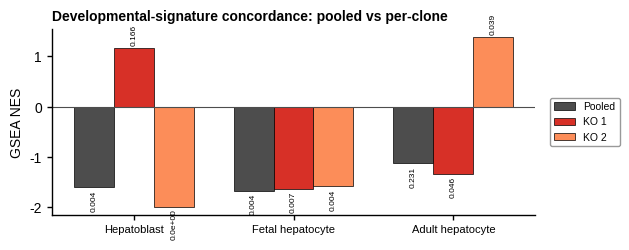

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 2.6))
terms = ['Hepatoblast_HB','Fetal_hepatocyte_FH','Adult_hepatocyte_AH']
w = 0.25
for i, contrast in enumerate(CONTRASTS):
    sub = devsig_all[devsig_all.contrast == contrast].set_index('Term').reindex(terms)
    x = np.arange(len(terms)) + (i - 1) * w
    ax.bar(x, sub['NES'], width=w, color=COLORS[contrast], edgecolor='black', linewidth=0.5, label=contrast)
    for xi, (nes, fdr) in zip(x, zip(sub['NES'], sub['FDR q-val'])):
        ax.text(xi, nes + (0.05 if nes >= 0 else -0.05), f'{fdr:.1e}' if fdr < 1e-3 else f'{fdr:.3f}',
                ha='center', va='bottom' if nes >= 0 else 'top', fontsize=6, rotation=90)
ax.axhline(0, color='0.3', lw=0.8)
ax.set_xticks(np.arange(len(terms))); ax.set_xticklabels(['Hepatoblast','Fetal hepatocyte','Adult hepatocyte'], fontsize=8)
ax.set_ylabel('GSEA NES', fontsize=AXTITLE)
ax.set_title('Developmental-signature concordance: pooled vs per-clone', fontsize=10, fontweight='bold', loc='left')
ax.legend(fontsize=7.5, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.8, edgecolor='grey')
plt.tight_layout()
fig.savefig('GSEA_clonecheck_developmental_signatures.pdf', bbox_inches='tight')
plt.show()

### Per-sample cross-check (already available, no missing files)

The pathway-level GSEA above tests gene-set enrichment in a ranked list; it's a different statistical
question from asking whether individual samples' average signature expression actually differs WT vs
KO. This cross-check is already fully computed (`DevSig_module_scores.csv`, from
`SLC38A4_KO_developmental_signature_analysis.ipynb`) and is repeated here for side-by-side reference
against the GSEA verdicts above. **It is not itself a manuscript figure** -- there is no "Fig. S10E"
in the current SI (Fig. S10 has panels A-D only); this was a stale internal cross-reference, corrected
2026-08-14. The developmental-signature GSEA result this notebook contributes to IS published, as
part of the Fig. S8B forest plot.

In [9]:
ms = pd.read_csv('DevSig_module_scores.csv', index_col=0)
ms['clone'] = ms.index.map(lambda s: 'KO 1' if s.startswith('C12') else ('KO 2' if s.startswith('P1_7') else 'WT'))

SIGS = ['Hepatoblast_HB','Fetal_hepatocyte_FH','Adult_hepatocyte_AH']
rows = []
wt = ms.loc[ms.clone == 'WT']
for sig in SIGS:
    for clone in ['KO 1','KO 2']:
        kv = ms.loc[ms.clone == clone, sig]
        _, p = mannwhitneyu(wt[sig], kv, alternative='two-sided')
        rows.append({'signature': sig, 'clone': clone,
                     'mean_WT': wt[sig].mean(), 'mean_clone': kv.mean(),
                     'direction': 'down' if kv.mean() < wt[sig].mean() else 'up',
                     'MWU_p': p})
per_sample_check = pd.DataFrame(rows)
per_sample_check

,signature,clone,mean_WT,mean_clone,direction,MWU_p
0,Hepatoblast_HB,KO 1,0.128878,0.307822,up,0.132035
1,Hepatoblast_HB,KO 2,0.128878,-0.436699,down,0.002165
2,Fetal_hepatocyte_FH,KO 1,0.206349,-0.082308,down,0.002165
3,Fetal_hepatocyte_FH,KO 2,0.206349,-0.124042,down,0.002165
4,Adult_hepatocyte_AH,KO 1,-0.093223,-0.313243,down,0.002165
5,Adult_hepatocyte_AH,KO 2,-0.093223,0.406466,up,0.002165


## Panel 3 — Curated gene-module concordance (cf. Fig. 3D / Table S6, local-gmt GSEA only)

`Fig3_KO_RNAseq_metabolism.ipynb` runs **nine** pathway-enrichment analyses in total for Fig. 3D/Table
S6: four Enrichr over-representation tests (KEGG, Reactome, GO:BP, GO:MF on the significant up/down gene
lists) and four/five pre-ranked GSEAs (KEGG_2021_Human, MSigDB_Hallmark_2020, Reactome_2022, and this
hand-curated module set `slc38a4_curated_modules.gmt`). Per your scope choice, this section covers the
**pre-ranked GSEA methods only** — starting with the one gene set that's a local file and needs no
internet: the 9 hand-curated modules (amino-acid transport, mTORC1/AA-stress, urea cycle, proliferation,
epithelial/mesenchymal identity, etc. — the same building blocks used throughout Figs. 3–4).

In [10]:
CURATED_GMT_CANDIDATES = ['slc38a4_curated_modules.gmt', 'reference/slc38a4_curated_modules.gmt']

def load_curated_gene_sets():
    for path in CURATED_GMT_CANDIDATES:
        if not os.path.exists(path):
            continue
        gs = {}
        with open(path) as fh:
            for line in fh:
                parts = line.rstrip('\n').split('\t')
                gs[parts[0]] = [g for g in parts[2:] if g]
        return gs
    raise FileNotFoundError(
        "Couldn't find 'slc38a4_curated_modules.gmt' (checked: " + ', '.join(CURATED_GMT_CANDIDATES) +
        "). Copy it next to this notebook from 06_Notebooks_for_GitHub/."
    )

curated_gene_sets = load_curated_gene_sets()
curated_rows = []
for contrast in CONTRASTS:
    df = run_prerank(contrast, curated_gene_sets, contrast, permutation_num=1000)  # match Fig3D's opt5_curated params (min_size=5 below)
    curated_rows.append(df)
curated_all = pd.concat(curated_rows, ignore_index=True)[['contrast','Term','ES','NES','NOM p-val','FDR q-val']]
curated_all.to_csv('GSEA_clonecheck_curated_modules.csv', index=False)
curated_all.sort_values(['Term','contrast'])

,contrast,Term,ES,NES,NOM p-val,FDR q-val
9,KO 1,Amino_acid_transport,-0.903299,-2.226838,0.000000,0.000000
20,KO 2,Amino_acid_transport,-0.847071,-2.043741,0.000000,0.000000
1,Pooled,Amino_acid_transport,-0.891250,-2.098019,0.000000,0.000000
14,KO 1,Epithelial_junction,0.649174,1.533433,0.048193,0.090770
22,KO 2,Epithelial_junction,0.706580,1.631570,0.017241,0.039224
4,Pooled,Epithelial_junction,0.697054,1.616424,0.021322,0.048871
13,KO 1,Glycine_serine_1C,-0.670835,-1.586155,0.033932,0.039142
23,KO 2,Glycine_serine_1C,-0.690852,-1.621896,0.029412,0.029530
5,Pooled,Glycine_serine_1C,-0.681169,-1.569648,0.034735,0.036413
15,KO 1,Inflammation_NFkB,0.732119,1.497566,0.076190,0.076884


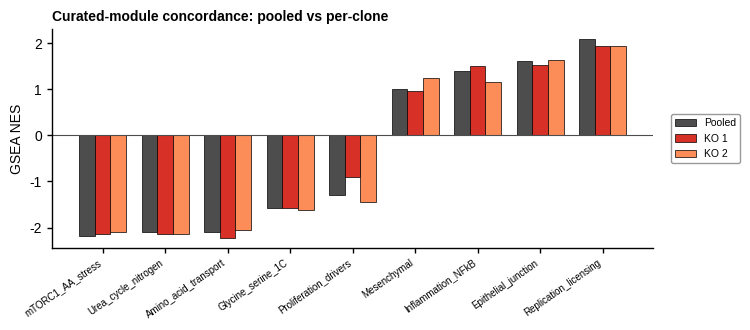

In [11]:
fig, ax = plt.subplots(figsize=(7.6, 3.4))
terms = curated_all.groupby('Term')['NES'].mean().sort_values().index.tolist()
w = 0.25
for i, contrast in enumerate(CONTRASTS):
    sub = curated_all[curated_all.contrast == contrast].set_index('Term').reindex(terms)
    x = np.arange(len(terms)) + (i - 1) * w
    ax.bar(x, sub['NES'], width=w, color=COLORS[contrast], edgecolor='black', linewidth=0.5, label=contrast)
ax.axhline(0, color='0.3', lw=0.8)
ax.set_xticks(np.arange(len(terms))); ax.set_xticklabels(terms, fontsize=7, rotation=35, ha='right')
ax.set_ylabel('GSEA NES', fontsize=AXTITLE)
ax.set_title('Curated-module concordance: pooled vs per-clone', fontsize=10, fontweight='bold', loc='left')
ax.legend(fontsize=7.5, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.8, edgecolor='grey')
plt.tight_layout()
fig.savefig('GSEA_clonecheck_curated_modules.pdf', bbox_inches='tight')
plt.show()

## Panel 4 — KEGG / Hallmark / Reactome GSEA (cf. Fig. 3D, Table S6)

The other three pre-ranked GSEA methods feeding Fig. 3D and Table S6 (`KEGG_2021_Human`,
`MSigDB_Hallmark_2020`, `Reactome_2022`) query Enrichr/MSigDB live the first time they run — the same
thing `Fig3_KO_RNAseq_metabolism.ipynb` itself does. Neither this notebook's original cloud-sandbox build
environment nor its device-bridge workspace had internet access to `maayanlab.cloud`, so this cell
**loads a cached copy (`GSEA_clonecheck_online_libraries.csv`) if one is already sitting next to this
notebook, and only re-queries Enrichr live if that cache is missing.** The cached copy here was generated
by running this exact cell locally, in an environment with internet access to Enrichr (the same one
`Fig3_KO_RNAseq_metabolism.ipynb` uses), reusing its exact library names/parameters (`seed=42,
permutation_num=1000`) applied to Pooled/KO1/KO2 rankings in turn. **To force a fresh recompute** (e.g.
after changing the ranking or parameters), delete `GSEA_clonecheck_online_libraries.csv` and re-run this
cell somewhere Enrichr is reachable.

In [12]:
# Uses a cached local copy if present (see markdown above); otherwise queries Enrichr/MSigDB live
# -- mirrors Fig3_KO_RNAseq_metabolism.ipynb's run_prerank() exactly, applied to Pooled/KO1/KO2 rankings.
ONLINE_LIBRARIES = {'KEGG_GSEA': 'KEGG_2021_Human', 'Hallmark_GSEA': 'MSigDB_Hallmark_2020',
                     'Reactome_GSEA': 'Reactome_2022'}
ONLINE_CACHE = 'GSEA_clonecheck_online_libraries.csv'

if os.path.exists(ONLINE_CACHE):
    print(f"Loading cached online-library GSEA results from '{ONLINE_CACHE}' "
          "(delete this file and re-run to recompute fresh where Enrichr is reachable).")
    online_all = pd.read_csv(ONLINE_CACHE)
else:
    online_rows = []
    for lib_label, lib_name in ONLINE_LIBRARIES.items():
        for contrast in CONTRASTS:
            df = run_prerank(contrast, lib_name, contrast, seed=42, permutation_num=1000)
            df['library'] = lib_label
            online_rows.append(df)
    online_all = pd.concat(online_rows, ignore_index=True)[['library','contrast','Term','ES','NES','NOM p-val','FDR q-val']]
    online_all.to_csv(ONLINE_CACHE, index=False)
online_all

Loading cached online-library GSEA results from 'GSEA_clonecheck_online_libraries.csv' (delete this file and re-run to recompute fresh where Enrichr is reachable).


,library,contrast,Term,ES,NES,NOM p-val,FDR q-val
0,KEGG_GSEA,Pooled,DNA replication,0.648837,2.144668,0.000000,0.000000
1,KEGG_GSEA,Pooled,Mismatch repair,0.666508,1.966931,0.000000,0.010286
2,KEGG_GSEA,Pooled,Cardiac muscle contraction,0.569155,1.945588,0.004474,0.010827
3,KEGG_GSEA,Pooled,Antigen processing and presentation,0.558640,1.878651,0.000000,0.020030
4,KEGG_GSEA,Pooled,Proteasome,0.541961,1.811573,0.002237,0.035729
...,...,...,...,...,...,...,...
5893,Reactome_GSEA,KO 2,Sensing Of DNA Double Strand Breaks R-HSA-5693548,0.241509,0.472530,0.994163,0.998422
5894,Reactome_GSEA,KO 2,IRAK2 Mediated Activation Of TAK1 Complex Upon...,0.183455,0.456169,0.986355,0.999108
5895,Reactome_GSEA,KO 2,TRAF6-mediated Induction Of TAK1 Complex Withi...,0.180103,0.452891,0.996063,0.998354
5896,Reactome_GSEA,KO 2,Passive Transport By Aquaporins R-HSA-432047,0.218125,0.442596,0.989960,0.998208


## Summary — is each claimed signature clone-robust?

One table, all signatures tested in this notebook, pooled NES/FDR next to each clone's NES/FDR/nominal
p, with an explicit concordance flag: **concordant** = both clones same NES sign; **discordant** =
clones disagree in sign (regardless of what the pooled result says).

In [13]:
def summarize(gsea_df):
    out = []
    for term in gsea_df['Term'].unique():
        sub = gsea_df[gsea_df.Term == term].set_index('contrast')
        nes1, nes2 = sub.loc['KO 1','NES'], sub.loc['KO 2','NES']
        out.append({
            'signature': term,
            'pooled_NES': sub.loc['Pooled','NES'], 'pooled_FDR': sub.loc['Pooled','FDR q-val'],
            'KO1_NES': nes1, 'KO1_p': sub.loc['KO 1','NOM p-val'],
            'KO2_NES': nes2, 'KO2_p': sub.loc['KO 2','NOM p-val'],
            'clone_concordant': bool(np.sign(nes1) == np.sign(nes2)),
        })
    return pd.DataFrame(out)

summary_parts = [summarize(sah_all), summarize(devsig_all), summarize(curated_all)]
try:
    online_all  # only defined if Panel 4's cell was actually run (needs internet)
    for lib in online_all['library'].unique():
        summary_parts.append(summarize(online_all[online_all.library == lib]))
except NameError:
    print("Panel 4 (KEGG/Hallmark/Reactome) wasn't run in this session (needs internet) -- "
          "excluded from the summary below. Run that cell, then re-run this one, to include it.")
summary = pd.concat(summary_parts, ignore_index=True)
summary['verdict'] = np.where(
    ~summary['clone_concordant'], 'DISCORDANT — do not cite as a coordinated effect',
    np.where((summary['KO1_p'] < 0.05) & (summary['KO2_p'] < 0.05), 'robust (concordant, both p<0.05)',
             'concordant but weak in >=1 clone'))
summary.to_csv('GSEA_clonecheck_summary.csv', index=False)
summary

,signature,pooled_NES,pooled_FDR,KO1_NES,KO1_p,KO2_NES,KO2_p,clone_concordant,verdict
0,SAH_UP,1.770313,0.000000,1.663278,0.000000,1.845407,0.000000,True,"robust (concordant, both p<0.05)"
1,SAH_DOWN,-1.438106,0.004510,-1.377475,0.011136,-1.199764,0.081986,True,concordant but weak in >=1 clone
2,Fetal_hepatocyte_FH,-1.678054,0.004366,-1.631683,0.001035,-1.583904,0.000000,True,"robust (concordant, both p<0.05)"
3,Hepatoblast_HB,-1.601659,0.004366,1.166611,0.140684,-1.982470,0.000000,False,DISCORDANT — do not cite as a coordinated effect
4,Adult_hepatocyte_AH,-1.127473,0.231374,-1.338188,0.087901,1.371278,0.061047,False,DISCORDANT — do not cite as a coordinated effect
...,...,...,...,...,...,...,...,...,...
1975,Pausing And Recovery Of Tat-mediated HIV Elong...,-0.497429,0.996413,0.850337,0.703934,-1.005857,0.441860,False,DISCORDANT — do not cite as a coordinated effect
1976,HDR Thru MMEJ (alt-NHEJ) R-HSA-5685939,-0.496300,0.995142,-0.744734,0.815094,0.612780,0.927894,False,DISCORDANT — do not cite as a coordinated effect
1977,Regulation Of IFNG Signaling R-HSA-877312,-0.489046,0.994800,-0.689765,0.870259,0.730124,0.824219,False,DISCORDANT — do not cite as a coordinated effect
1978,Insulin Receptor Recycling R-HSA-77387,-0.442668,0.998514,-1.245756,0.186373,0.898470,0.592593,False,DISCORDANT — do not cite as a coordinated effect


## Supplementary panel — Fig. S8B, compact forest plot

Assigned as **Fig. S8B**, the second panel of the Fig. S8 supplementary figure (KEGG pathway enrichment
in the SLC38A4 knockout, supporting Fig. 3D) — Fig. S8A already shows the leading-edge genes behind these
same 8 KEGG terms (bar chart + per-sample heatmap); this panel is the per-clone robustness companion,
answering "does this hold in both clones" for the Fig. 3D pathway story, plus the SAH- and
developmental-signature claims it also covers. One row per signature, WT/KO1/KO2 NES as three points,
filled = nominally significant.

**Row order follows the figures in the manuscript**: Fig. 3D's 8 KEGG_2021_Human terms first (Antigen
processing, Proteasome, ER protein processing, Protein export, Gly/Ser/Thr metabolism, Complement &
coagulation, Arginine biosynthesis, Cys/Met metabolism — confirmed by matching FDR q-values against the
pooled-model cache in `enrichment_cache_FDR0.05_FC1/_cache_prerank_opt6_kegg_gsea.csv`), then SAH-up/SAH-
down (Fig. 4E), then the one developmental signature that held up as clone-concordant, Fetal hepatocyte. Hepatoblast and Adult hepatocyte are excluded (they're the discordant ones, see Panel 2) and
the 9 hand-curated modules (Panel 3) are omitted too, since they aren't what's plotted in Fig. 3D.

**No robust/weak/discordant colour-coding** — with the discordant signatures already excluded, almost
every remaining point is nominally significant in both clones, so a verdict layer added noise rather
than signal; significance is still shown via filled vs. open markers. The "Pooled" (KO1+KO2 combined vs
WT) series is labelled **WT** here to match how it's referred to elsewhere, and plotted as a **black
circle** rather than a grey square.

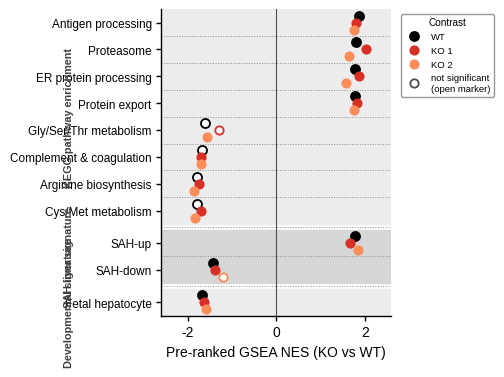

In [14]:
from matplotlib.lines import Line2D

FOREST_CATEGORIES = [
    ('KEGG pathway enrichment',   ['Antigen processing and presentation', 'Proteasome',
                                    'Protein processing in endoplasmic reticulum', 'Protein export',
                                    'Glycine, serine and threonine metabolism',
                                    'Complement and coagulation cascades',
                                    'Arginine biosynthesis', 'Cysteine and methionine metabolism']),
    ('SAH liver signature',       ['SAH_UP', 'SAH_DOWN']),
    ('Developmental signature',   ['Fetal_hepatocyte_FH']),
]
NICE_LABEL = {
    'SAH_UP': 'SAH-up', 'SAH_DOWN': 'SAH-down',
    'Fetal_hepatocyte_FH': 'Fetal hepatocyte',
    'Antigen processing and presentation': 'Antigen processing',
    'Proteasome': 'Proteasome',
    'Protein processing in endoplasmic reticulum': 'ER protein processing',
    'Protein export': 'Protein export',
    'Glycine, serine and threonine metabolism': 'Gly/Ser/Thr metabolism',
    'Complement and coagulation cascades': 'Complement & coagulation',
    'Arginine biosynthesis': 'Arginine biosynthesis',
    'Cysteine and methionine metabolism': 'Cys/Met metabolism',
}
summary_idx = summary.set_index('signature')
forest_rows = []
for cat_label, sigs in FOREST_CATEGORIES:
    for sig in sigs:
        if sig not in summary_idx.index:
            continue
        r = summary_idx.loc[sig]
        forest_rows.append(dict(label=NICE_LABEL[sig], category=cat_label,
            wt=r['pooled_NES'], ko1=r['KO1_NES'], ko2=r['KO2_NES'],
            wt_sig=r['pooled_FDR'] < 0.05, ko1_sig=r['KO1_p'] < 0.05, ko2_sig=r['KO2_p'] < 0.05))

n = len(forest_rows)
GAP = 0.2  # small breathing space between category blocks -- set to 0 for fully seamless bands
n_gaps = len(FOREST_CATEGORIES) - 1
fig, ax = plt.subplots(figsize=(5, 0.3 * n + GAP * n_gaps * 0.2 + 0.6))

y_list, cur_y, prev_cat = [], float(n - 1) + GAP * n_gaps, None
for r in forest_rows:
    if prev_cat is not None and r['category'] != prev_cat:
        cur_y -= GAP
    y_list.append(cur_y); cur_y -= 1.0; prev_cat = r['category']
y = np.array(y_list)

# alternating background band per category (2 shades of grey), instead of per-row verdict shading
BAND_COLORS = ['#ececec', '#d6d6d6']
cat_ycenter = {}
for ci, (cat_label, sigs) in enumerate(FOREST_CATEGORIES):
    idxs = [i for i, r in enumerate(forest_rows) if r['category'] == cat_label]
    if not idxs:
        continue
    ytop, ybot = y[idxs[0]], y[idxs[-1]]
    ax.axhspan(ybot - 0.5, ytop + 0.5, color=BAND_COLORS[ci % 2], zorder=0)
    cat_ycenter[cat_label] = (ytop + ybot) / 2

# dotted divider between every consecutive GSEA row (within AND across categories)
for yi, yj in zip(y[:-1], y[1:]):
    ax.axhline((yi + yj) / 2, color='0.55', lw=0.7, ls=':', zorder=2)

GROUP_COLOR = {'WT': 'black', 'KO 1': COLORS['KO 1'], 'KO 2': COLORS['KO 2']}
BAND = 0.42
offsets = {'WT': BAND * 0.62, 'KO 1': 0.0, 'KO 2': -BAND * 0.62}
for yi, r in zip(y, forest_rows):
    for grp, key, sig in [('WT', 'wt', 'wt_sig'), ('KO 1', 'ko1', 'ko1_sig'), ('KO 2', 'ko2', 'ko2_sig')]:
        face = GROUP_COLOR[grp] if r[sig] else 'white'
        ax.plot(r[key], yi + offsets[grp], marker='o', ms=6.5 if grp == 'WT' else 6,
                 mfc=face, mec=GROUP_COLOR[grp], mew=1.3, ls='none', zorder=4)

ax.axvline(0, color='0.3', lw=0.8, zorder=1)
ax.set_yticks(y); ax.set_yticklabels([r['label'] for r in forest_rows], fontsize=8.5)
ax.set_ylim(y.min() - 0.5, y.max() + 0.5)
ax.set_xlabel('Pre-ranked GSEA NES (KO vs WT)', fontsize=AXTITLE)
ax.set_xlim(-2.6, 2.6)

# category labels on the left, vertical, centred on each block
for cat_label, y_center in cat_ycenter.items():
    ax.annotate(cat_label, xy=(-0.4, y_center), xycoords=('axes fraction', 'data'),
                rotation=90, ha='center', va='center', fontsize=7.8, fontweight='bold', color='0.25')

marker_handles = [
    Line2D([0], [0], marker='o', color='w', mfc='black', mec='black', mew=1.3, ms=6.5, label='WT'),
    Line2D([0], [0], marker='o', color='w', mfc=COLORS['KO 1'], mec=COLORS['KO 1'], mew=1.3, ms=6, label='KO 1'),
    Line2D([0], [0], marker='o', color='w', mfc=COLORS['KO 2'], mec=COLORS['KO 2'], mew=1.3, ms=6, label='KO 2'),
    Line2D([0], [0], marker='o', color='w', mfc='white', mec='0.3', mew=1.3, ms=6, label='not significant\n(open marker)'),
]
ax.legend(handles=marker_handles, fontsize=6.8, loc='upper left', bbox_to_anchor=(1.02, 1.0),
          frameon=True, framealpha=0.8, edgecolor='grey', title='Contrast', title_fontsize=7.2)
fig.subplots_adjust(left=0.44)
fig.savefig('Fig_S8B_clone_robustness_forest.pdf', bbox_inches='tight')
plt.show()